# Klasifikasi Tumor Otak MRI: VGG-16, ResNet-101, GoogLeNet (versi final)

**Cara pakai:** jalankan cell dari atas ke bawah, jangan loncat. Otomatis memakai GPU kalau tersedia (Colab), dan CPU kalau tidak.
Kalau kernel restart: **Run All Above** sampai bagian 7, lalu lanjut ke model yang belum selesai
(model yang sudah selesai otomatis di-load dari folder hasil, tidak training ulang).

**Perbedaan dari versi sebelumnya**

| Perubahan | Alasan |
|---|---|
| Duplikat dibuang + split stratified | Test set bebas dari gambar kembar, proporsi kelas merata |
| Statistik BatchNorm dibekukan saat training | Di log lama, val loss ResNet/GoogLeNet loncat-loncat (0.33 - 1.03) padahal train loss stabil; itu gejala khas statistik BatchNorm yang ikut berubah walau backbone "dibekukan" |
| LR tahap 1 = 1e-3, tahap 2 = 1e-4 | Hasil percobaan: 1e-2 tidak stabil |
| Otomatis GPU/CPU + dukungan Google Colab | Sesuai proposal (Colab GPU), jauh lebih cepat dari CPU |
| Prediksi & riwayat training disimpan | Bisa dianalisis ulang tanpa training ulang |
| Interval kepercayaan (bootstrap) + uji McNemar | Supaya klaim "model terbaik" dan "fine-tuning meningkatkan" punya dasar statistik |

| Bagian | Isi |
|---|---|
| 0 | Import & konfigurasi |
| 1 | Eksplorasi data |
| 2 | Muat data & cek duplikat |
| 3 | Transform & augmentasi |
| 4 | Buang duplikat + split stratified 80:10:10 |
| 5 | Bangun model |
| 6 | Fungsi training & evaluasi |
| 7 | Pipeline per arsitektur |
| 8-10 | Jalankan VGG-16, ResNet-101, GoogLeNet |
| 11 | Ringkasan, interval kepercayaan, uji statistik |


## 0. Import & Konfigurasi

In [1]:
import os, sys, copy, time, json, random, hashlib, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.model_selection import train_test_split
from scipy.stats import binomtest

# --- Lokasi project ---
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/Skripsi"     # folder di Google Drive berisi folder "dataset"
else:
    PROJECT_DIR = r"D:\Skripsi"

if os.path.isdir(PROJECT_DIR):
    os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

# --- Lokasi dataset ---
DATA_DIR = "dataset"
if IN_COLAB:
    # Baca dari disk lokal Colab (jauh lebih cepat daripada langsung dari Drive)
    LOCAL_DATA = "/content/dataset"
    if not os.path.isdir(LOCAL_DATA):
        print("Menyalin dataset dari Drive ke disk lokal Colab (sekali saja)...")
        shutil.copytree(os.path.join(PROJECT_DIR, "dataset"), LOCAL_DATA)
    DATA_DIR = LOCAL_DATA

Working directory: D:\Skripsi


In [2]:
# ===== KONFIGURASI EKSPERIMEN =====
IMG_SIZE = 224
BATCH_SIZE = 32

LR_BEFORE = 1e-3          # tahap 1: classifier head saja
LR_FT = 1e-4              # tahap 2: fine-tuning
EARLY_STOP_PATIENCE = 5
MAX_EPOCHS = 30
ROTATION_DEG = 15

SEED = 42

# Hasil disimpan di folder project (di Colab: di Google Drive, jadi aman kalau runtime terputus)
BASE_DIR = PROJECT_DIR if os.path.isdir(PROJECT_DIR) else "."
RESULTS_DIR = os.path.join(BASE_DIR, "results_final")
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
PIN_MEMORY = DEVICE.type == "cuda"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

print("Torch version :", torch.__version__)
print("Device        :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
print("LR tahap 1    :", LR_BEFORE, "| LR fine-tuning:", LR_FT)
print("Folder hasil  :", RESULTS_DIR)

Torch version : 2.11.0+cpu
Device        : cpu | CPU
LR tahap 1    : 0.001 | LR fine-tuning: 0.0001
Folder hasil  : D:\Skripsi\results_final


## Eksplorasi Data

In [3]:
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Testing")

def count_images_per_class(folder_path):
    counts = {}
    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
    return counts

df_counts = pd.DataFrame({
    "Training": count_images_per_class(TRAIN_DIR),
    "Testing": count_images_per_class(TEST_DIR)
}).fillna(0).astype(int)
df_counts["Total"] = df_counts["Training"] + df_counts["Testing"]
df_counts["Persentase (%)"] = (df_counts["Total"] / df_counts["Total"].sum() * 100).round(2)
df_counts.loc["TOTAL"] = df_counts.sum()
df_counts

,Training,Testing,Total,Persentase (%)
glioma,1400.0,400.0,1800.0,25.0
meningioma,1400.0,400.0,1800.0,25.0
notumor,1400.0,400.0,1800.0,25.0
pituitary,1400.0,400.0,1800.0,25.0
TOTAL,5600.0,1600.0,7200.0,100.0


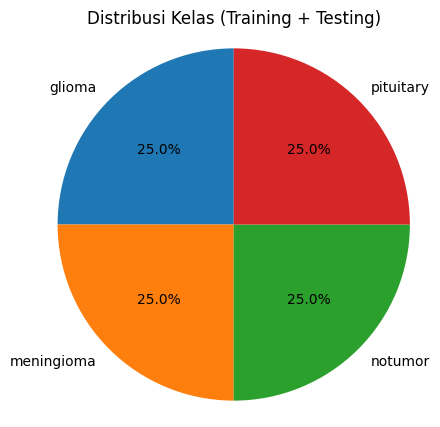

In [4]:
class_only = df_counts.drop(index="TOTAL")
plt.figure(figsize=(5, 5))
plt.pie(class_only["Total"], labels=class_only.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribusi Kelas (Training + Testing)")
plt.axis("equal")
plt.show()

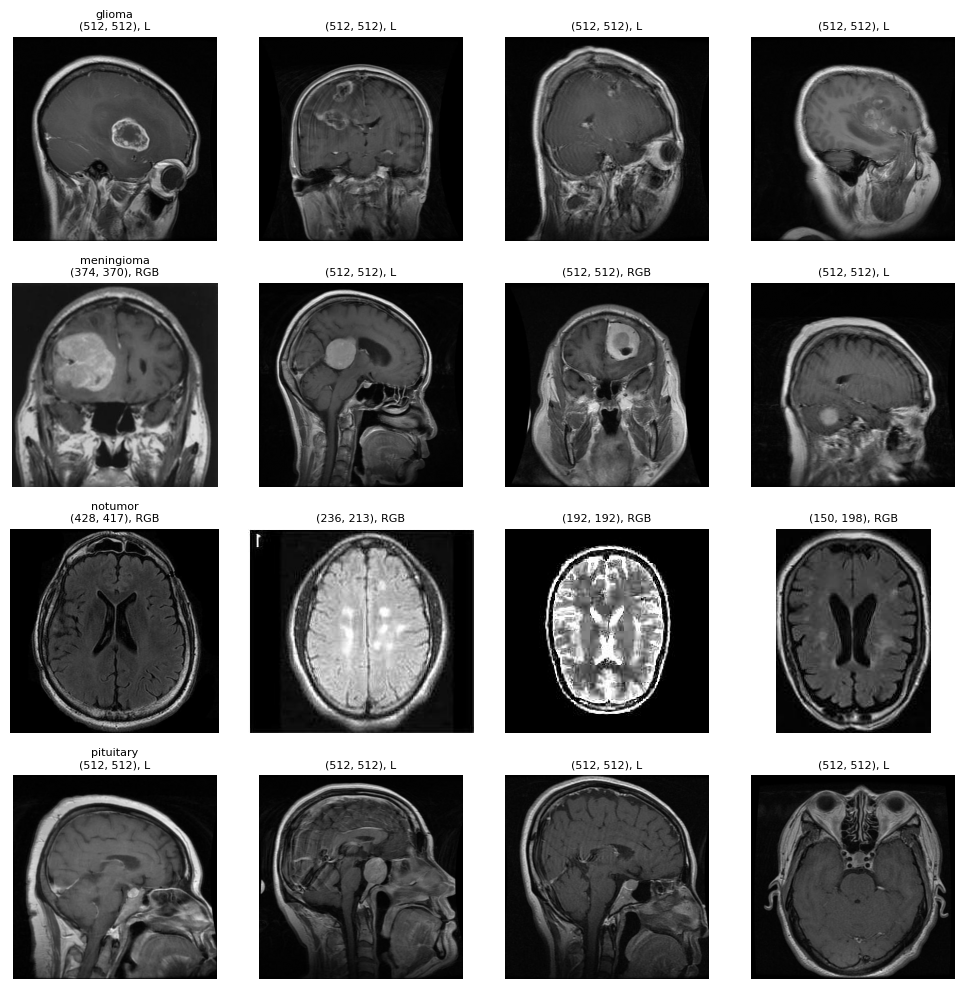

In [5]:
def show_sample_images(folder_path, n_per_class=4):
    class_names_ = sorted(os.listdir(folder_path))
    fig, axes = plt.subplots(len(class_names_), n_per_class,
                             figsize=(n_per_class * 2.5, len(class_names_) * 2.5))
    for row, cname in enumerate(class_names_):
        cpath = os.path.join(folder_path, cname)
        files = [f for f in os.listdir(cpath) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        for col, fname in enumerate(random.sample(files, min(n_per_class, len(files)))):
            img = Image.open(os.path.join(cpath, fname))
            ax = axes[row, col]
            ax.imshow(img, cmap="gray")
            ax.axis("off")
            ax.set_title(f"{cname}\n{img.size}, {img.mode}" if col == 0 else f"{img.size}, {img.mode}", fontsize=8)
    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR, n_per_class=4)

In [6]:
# Cek ukuran & mode warna (sampel 200 gambar per kelas)
sizes, modes = set(), set()
for cname in sorted(os.listdir(TRAIN_DIR)):
    cpath = os.path.join(TRAIN_DIR, cname)
    for fname in os.listdir(cpath)[:200]:
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            with Image.open(os.path.join(cpath, fname)) as img:
                sizes.add(img.size)
                modes.add(img.mode)
print("Ukuran unik     :", sizes)
print("Mode warna unik :", modes)

Ukuran unik     : {(420, 280), (206, 244), (800, 693), (393, 400), (387, 469), (200, 252), (201, 251), (453, 496), (318, 354), (441, 442), (236, 226), (470, 432), (1275, 1427), (150, 198), (227, 262), (528, 528), (203, 243), (207, 243), (234, 224), (890, 1075), (208, 278), (442, 454), (232, 217), (374, 456), (236, 269), (296, 320), (626, 686), (276, 326), (256, 256), (359, 449), (201, 250), (257, 248), (192, 192), (538, 548), (236, 280), (225, 225), (262, 244), (410, 490), (275, 183), (366, 395), (218, 231), (680, 680), (350, 350), (214, 236), (442, 442), (173, 201), (230, 235), (1338, 1304), (236, 220), (497, 398), (216, 293), (236, 250), (494, 600), (210, 240), (228, 221), (755, 824), (236, 213), (234, 225), (504, 540), (227, 222), (235, 244), (236, 252), (350, 393), (416, 512), (630, 630), (405, 484), (275, 301), (236, 236), (512, 512), (212, 238), (215, 234), (196, 257), (236, 357), (226, 212), (236, 366), (339, 415), (428, 417), (354, 443), (468, 444), (194, 259), (642, 361), (177

## Muat Data & Cek Duplikat

Training + Testing digabung jadi satu pool. Setiap file dihitung hash-nya untuk mendeteksi gambar identik persis,
baik di dalam satu folder maupun lintas folder.

In [7]:
train_folder_raw = datasets.ImageFolder(TRAIN_DIR, transform=None)
test_folder_raw = datasets.ImageFolder(TEST_DIR, transform=None)

class_names = train_folder_raw.classes
assert train_folder_raw.classes == test_folder_raw.classes, "Urutan kelas Training dan Testing harus sama!"
print("Kelas (urutan index):", class_names)

# Urutan all_samples sama persis dengan urutan index di ConcatDataset
all_samples = train_folder_raw.samples + test_folder_raw.samples      # list of (path, label)
combined_dataset = torch.utils.data.ConcatDataset([train_folder_raw, test_folder_raw])
n_train_orig = len(train_folder_raw.samples)
print("Total gambar pool gabungan:", len(all_samples))

with open(os.path.join(RESULTS_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

Kelas (urutan index): ['glioma', 'meningioma', 'notumor', 'pituitary']
Total gambar pool gabungan: 7200


In [8]:
def md5_of(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("Menghitung hash semua file (sekitar 1-2 menit)...")
all_hashes = [md5_of(p) for p, _ in all_samples]

hash_groups = {}
for idx, h in enumerate(all_hashes):
    hash_groups.setdefault(h, []).append(idx)

dup_groups = {h: ix for h, ix in hash_groups.items() if len(ix) > 1}
n_extra_copies = sum(len(ix) - 1 for ix in dup_groups.values())

cross = [ix for ix in dup_groups.values()
         if any(i < n_train_orig for i in ix) and any(i >= n_train_orig for i in ix)]
label_conflict = [ix for ix in dup_groups.values() if len({all_samples[i][1] for i in ix}) > 1]

print(f"File total                       : {len(all_samples)}")
print(f"File unik (hash berbeda)         : {len(hash_groups)}")
print(f"Kelompok gambar duplikat         : {len(dup_groups)}")
print(f"Salinan berlebih (akan dibuang)  : {n_extra_copies}")
print(f"Duplikat lintas Training-Testing : {len(cross)} kelompok")
print(f"Duplikat dengan label berbeda    : {len(label_conflict)} kelompok")

Menghitung hash semua file (sekitar 1-2 menit)...
File total                       : 7200
File unik (hash berbeda)         : 7013
Kelompok gambar duplikat         : 153
Salinan berlebih (akan dibuang)  : 187
Duplikat lintas Training-Testing : 0 kelompok
Duplikat dengan label berbeda    : 0 kelompok


## Transform & Augmentasi

Augmentasi dinamis (on-the-fly): hanya untuk data train dan tidak menambah jumlah file.
Gambar sumber sudah persegi (512x512), jadi resize ke 224x224 tidak menggepengkan citra.

In [9]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=ROTATION_DEG),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])
print("Transform siap.")

Transform siap.


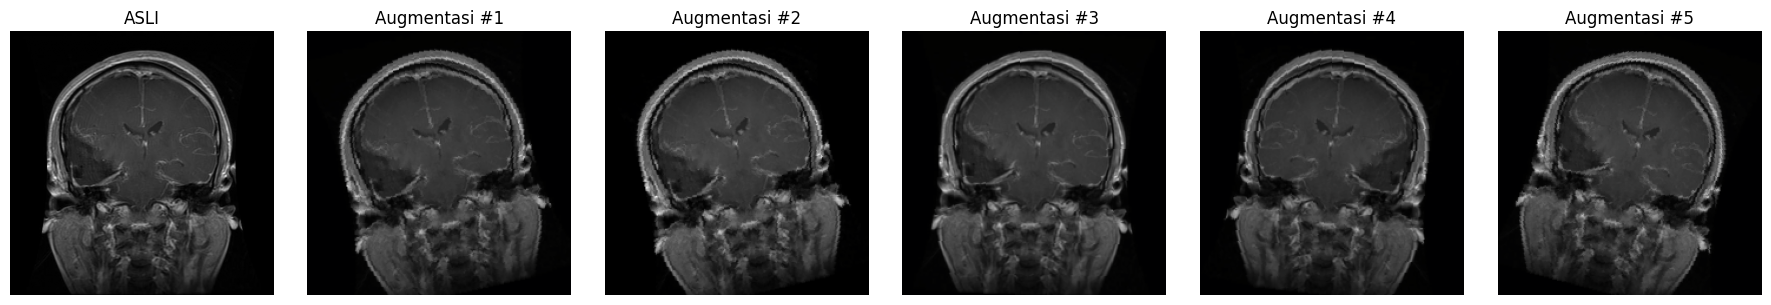

In [10]:
# Demo: 1 file asli -> beberapa tampilan hasil augmentasi (jumlah file tetap)
sample_path, _ = all_samples[0]
original_img = Image.open(sample_path)

n_versions = 5
fig, axes = plt.subplots(1, n_versions + 1, figsize=(3 * (n_versions + 1), 3))
axes[0].imshow(original_img, cmap="gray")
axes[0].set_title("ASLI")
axes[0].axis("off")
for i in range(1, n_versions + 1):
    t = train_transform(original_img)
    im = np.clip(np.array(imagenet_std) * t.permute(1, 2, 0).numpy() + np.array(imagenet_mean), 0, 1)
    axes[i].imshow(im)
    axes[i].set_title(f"Augmentasi #{i}")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## Buang Duplikat & Split Stratified 80:10:10

1. Dari setiap kelompok gambar identik, hanya **1 salinan** dipertahankan.
2. Split **stratified** (proporsi tiap kelas sama di train/val/test).
3. Dicek otomatis bahwa tidak ada gambar identik di dua subset berbeda.

In [11]:
# 1) Buang duplikat: pertahankan salinan pertama tiap hash
unique_idx = sorted(ix[0] for ix in hash_groups.values())
unique_labels = [all_samples[i][1] for i in unique_idx]
print(f"Sebelum dedup: {len(all_samples)} | Sesudah dedup: {len(unique_idx)}")

# 2) Split stratified 80 / 10 / 10
train_indices, temp_idx = train_test_split(
    unique_idx, test_size=0.20, stratify=unique_labels, random_state=SEED)
temp_labels = [all_samples[i][1] for i in temp_idx]
val_indices, test_indices = train_test_split(
    temp_idx, test_size=0.50, stratify=temp_labels, random_state=SEED)

n_all = len(unique_idx)
print(f"Train: {len(train_indices)} ({len(train_indices)/n_all*100:.1f}%)")
print(f"Val  : {len(val_indices)} ({len(val_indices)/n_all*100:.1f}%)")
print(f"Test : {len(test_indices)} ({len(test_indices)/n_all*100:.1f}%)")

# 3) Cek: tidak ada hash yang sama antar subset
h_train = {all_hashes[i] for i in train_indices}
h_val = {all_hashes[i] for i in val_indices}
h_test = {all_hashes[i] for i in test_indices}
assert not (h_train & h_val), "Ada gambar identik di train dan val!"
assert not (h_train & h_test), "Ada gambar identik di train dan test!"
assert not (h_val & h_test), "Ada gambar identik di val dan test!"
print("Cek kebocoran duplikat antar subset: AMAN (tidak ada gambar identik lintas subset)")

def dist(indices):
    labs = [class_names[all_samples[i][1]] for i in indices]
    return pd.Series(labs).value_counts().reindex(class_names)

pd.DataFrame({"Train": dist(train_indices), "Val": dist(val_indices), "Test": dist(test_indices)})

Sebelum dedup: 7200 | Sesudah dedup: 7013
Train: 5610 (80.0%)
Val  : 701 (10.0%)
Test : 702 (10.0%)
Cek kebocoran duplikat antar subset: AMAN (tidak ada gambar identik lintas subset)


,Train,Val,Test
glioma,1429,178,179
meningioma,1427,178,179
notumor,1345,168,168
pituitary,1409,177,176


In [12]:
class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, label = self.base_dataset[self.indices[idx]]
        if self.transform is not None:
            img = self.transform(img)
        return img, label

train_dataset = TransformSubset(combined_dataset, train_indices, train_transform)
val_dataset = TransformSubset(combined_dataset, val_indices, eval_transform)
test_dataset = TransformSubset(combined_dataset, test_indices, eval_transform)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

images, labels = next(iter(train_loader))
print("Shape 1 batch:", images.shape, "| label:", labels[:10].tolist())

Shape 1 batch: torch.Size([32, 3, 224, 224]) | label: [3, 2, 0, 0, 3, 1, 0, 1, 2, 0]


## Bangun Model (Transfer Learning)

Tahap 1: backbone dibekukan, hanya classifier head yang dilatih.
Tahap 2: lapisan terdalam dibuka untuk fine-tuning.

In [13]:
NUM_CLASSES = len(class_names)

def build_model(arch, num_classes=NUM_CLASSES):
    if arch == "vgg16":
        model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    elif arch == "resnet101":
        model = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V2)
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif arch == "googlenet":
        model = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1)
        model.aux_logits = False
        model.aux1 = None
        model.aux2 = None
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")

    return model.to(DEVICE)


def unfreeze_deep_layers(model, arch):
    # Buka lapisan konvolusi terdalam untuk fine-tuning
    if arch == "vgg16":
        for name, p in model.named_parameters():
            if name.startswith(("features.24", "features.26", "features.28", "classifier")):
                p.requires_grad = True
    elif arch == "resnet101":
        for name, p in model.named_parameters():
            if name.startswith(("layer4", "fc")):
                p.requires_grad = True
    elif arch == "googlenet":
        for name, p in model.named_parameters():
            if name.startswith(("inception5", "fc")):
                p.requires_grad = True
    return model


def set_bn_eval(model):
    # Bekukan statistik BatchNorm (running mean/var). Tanpa ini, BatchNorm pada backbone
    # yang "dibeku" tetap berubah tiap batch dan membuat val loss tidak stabil.
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.eval()

# Cek cepat jumlah parameter (VGG-16)
_m = build_model("vgg16")
print("Total parameter        :", f"{sum(p.numel() for p in _m.parameters()):,}")
print("Trainable (sebelum FT) :", f"{sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
del _m

Total parameter        : 134,276,932
Trainable (sebelum FT) : 16,388


## Fungsi Training, Evaluasi, Plot

In [14]:
def train_model(model, train_loader, val_loader, lr, max_epochs, patience, stage_name=""):
    criterion = nn.CrossEntropyLoss()
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(trainable_params, lr=lr)

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, max_epochs + 1):
        t0 = time.time()

        model.train()
        set_bn_eval(model)          # statistik BatchNorm tidak ikut berubah
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                outputs = model(inputs)
                val_loss += criterion(outputs, labels).item() * inputs.size(0)
                correct += (outputs.argmax(dim=1) == labels).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"[{stage_name}] Epoch {epoch:02d} | train_loss={train_loss:.4f} "
              f"| val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | {time.time()-t0:.1f}s")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"[{stage_name}] Early stopping di epoch {epoch}.")
                break

    model.load_state_dict(best_state)
    return model, history

In [15]:
def evaluate_model(model, test_loader, class_names, stage_name=""):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs.to(DEVICE))
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.numpy())
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average="macro", zero_division=0)
    rec = recall_score(all_labels, all_preds, average="macro", zero_division=0)
    f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)

    print(f"\n===== HASIL EVALUASI [{stage_name}] =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}\n")
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(5, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix - {stage_name}")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=45)
    plt.yticks(range(len(class_names)), class_names)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.ylabel("Label Asli")
    plt.xlabel("Label Prediksi")
    plt.tight_layout()
    plt.show()

    metrics = {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}
    return metrics, all_preds, all_labels


def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["val_loss"], label="Val Loss")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history["val_acc"], label="Val Accuracy", color="green")
    axes[1].set_title(f"Val Accuracy - {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## Pipeline per Arsitektur

In [16]:
def run_pipeline(arch):
    print(f"\n{'='*60}\nARSITEKTUR: {arch.upper()}\n{'='*60}")
    model = build_model(arch)

    print(">>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)")
    model, hist_before = train_model(
        model, train_loader, val_loader,
        lr=LR_BEFORE, max_epochs=MAX_EPOCHS, patience=EARLY_STOP_PATIENCE,
        stage_name=f"{arch}-before-FT"
    )
    plot_history(hist_before, title=f"{arch} - Sebelum Fine-Tuning")
    metrics_before, preds_before, labels_test = evaluate_model(
        model, test_loader, class_names, stage_name=f"{arch} - Sebelum FT")

    print(">>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)")
    model = unfreeze_deep_layers(model, arch)
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable parameter setelah unfreeze: {n_trainable:,}")

    model, hist_ft = train_model(
        model, train_loader, val_loader,
        lr=LR_FT, max_epochs=MAX_EPOCHS, patience=EARLY_STOP_PATIENCE,
        stage_name=f"{arch}-fine-tuning"
    )
    plot_history(hist_ft, title=f"{arch} - Fine-Tuning")
    metrics_after, preds_after, _ = evaluate_model(
        model, test_loader, class_names, stage_name=f"{arch} - Sesudah FT")

    print(f"\nRingkasan {arch}:")
    print(f"  Sebelum FT -> F1: {metrics_before['f1']:.4f}, Accuracy: {metrics_before['accuracy']:.4f}")
    print(f"  Sesudah FT -> F1: {metrics_after['f1']:.4f}, Accuracy: {metrics_after['accuracy']:.4f}")
    print(f"  Peningkatan F1  : {metrics_after['f1'] - metrics_before['f1']:+.4f}")

    # Simpan semua artefak (model, metrik, prediksi, riwayat training)
    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{arch}_finetuned.pth"))
    np.savez(os.path.join(RESULTS_DIR, f"{arch}_preds.npz"),
             labels=labels_test, before=preds_before, after=preds_after)
    with open(os.path.join(RESULTS_DIR, f"{arch}_history.json"), "w") as f:
        json.dump({"before": hist_before, "ft": hist_ft}, f)
    with open(os.path.join(RESULTS_DIR, f"{arch}_metrics.json"), "w") as f:   # ditulis terakhir = tanda selesai
        json.dump({"before": metrics_before, "after": metrics_after}, f, indent=2)

    return {"arch": arch, "before": metrics_before, "after": metrics_after}


def run_or_load(arch):
    path = os.path.join(RESULTS_DIR, f"{arch}_metrics.json")
    if os.path.exists(path):
        print(f"[{arch}] Hasil sudah ada di {path}, training dilewati.")
        with open(path, "r") as f:
            m = json.load(f)
        return {"arch": arch, "before": m["before"], "after": m["after"]}
    return run_pipeline(arch)


all_results = {}

## VGG-16



ARSITEKTUR: VGG16
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[vgg16-before-FT] Epoch 01 | train_loss=0.6768 | val_loss=0.5080 | val_acc=0.7703 | 915.6s
[vgg16-before-FT] Epoch 02 | train_loss=0.5701 | val_loss=0.4686 | val_acc=0.8417 | 890.9s
[vgg16-before-FT] Epoch 03 | train_loss=0.5515 | val_loss=0.4172 | val_acc=0.8445 | 895.7s
[vgg16-before-FT] Epoch 04 | train_loss=0.5495 | val_loss=0.4478 | val_acc=0.8174 | 893.2s
[vgg16-before-FT] Epoch 05 | train_loss=0.5454 | val_loss=0.4399 | val_acc=0.8302 | 887.2s
[vgg16-before-FT] Epoch 06 | train_loss=0.5350 | val_loss=0.4178 | val_acc=0.8345 | 905.7s
[vgg16-before-FT] Epoch 07 | train_loss=0.5396 | val_loss=0.4434 | val_acc=0.8160 | 935.7s
[vgg16-before-FT] Epoch 08 | train_loss=0.5232 | val_loss=0.3957 | val_acc=0.8459 | 922.6s
[vgg16-before-FT] Epoch 09 | train_loss=0.5176 | val_loss=0.3759 | val_acc=0.8716 | 878.5s
[vgg16-before-FT] Epoch 10 | train_loss=0.5365 | val_loss=0.4408 | val_acc=0.8231 | 891.0s
[vgg16

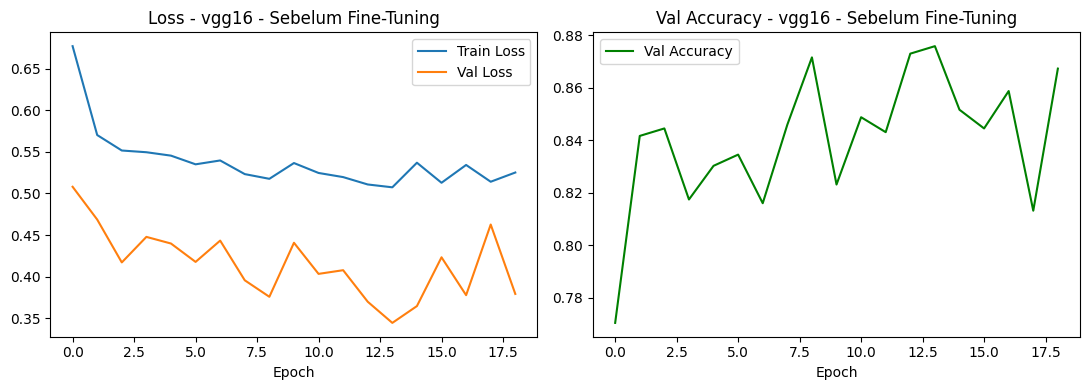


===== HASIL EVALUASI [vgg16 - Sebelum FT] =====
Accuracy : 0.8917
Precision: 0.8935
Recall   : 0.8927
F1-Score : 0.8930

              precision    recall  f1-score   support

      glioma       0.89      0.87      0.88       179
  meningioma       0.80      0.82      0.81       179
     notumor       0.95      0.94      0.94       168
   pituitary       0.94      0.94      0.94       176

    accuracy                           0.89       702
   macro avg       0.89      0.89      0.89       702
weighted avg       0.89      0.89      0.89       702



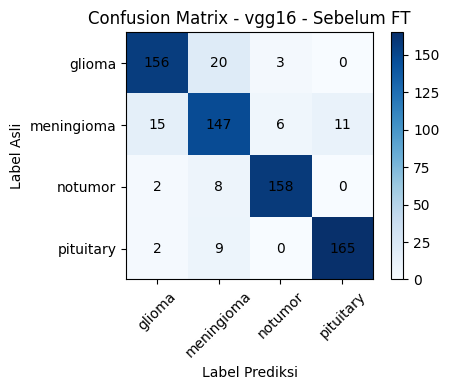

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 126,641,668
[vgg16-fine-tuning] Epoch 01 | train_loss=0.3773 | val_loss=0.2069 | val_acc=0.9301 | 1200.2s
[vgg16-fine-tuning] Epoch 02 | train_loss=0.2009 | val_loss=0.3760 | val_acc=0.8802 | 1200.3s
[vgg16-fine-tuning] Epoch 03 | train_loss=0.1433 | val_loss=0.2273 | val_acc=0.9287 | 1064.3s
[vgg16-fine-tuning] Epoch 04 | train_loss=0.1130 | val_loss=0.1768 | val_acc=0.9458 | 1107.7s
[vgg16-fine-tuning] Epoch 05 | train_loss=0.0871 | val_loss=0.1776 | val_acc=0.9586 | 1010.2s
[vgg16-fine-tuning] Epoch 06 | train_loss=0.0932 | val_loss=0.1467 | val_acc=0.9601 | 1166.3s
[vgg16-fine-tuning] Epoch 07 | train_loss=0.0594 | val_loss=0.1148 | val_acc=0.9629 | 1144.8s
[vgg16-fine-tuning] Epoch 08 | train_loss=0.0646 | val_loss=0.1656 | val_acc=0.9501 | 1108.8s
[vgg16-fine-tuning] Epoch 09 | train_loss=0.0448 | val_loss=0.2155 | val_acc=0.9601 | 1095.2s
[vgg16-fine-tuning] Epoch 10 | train_loss=0

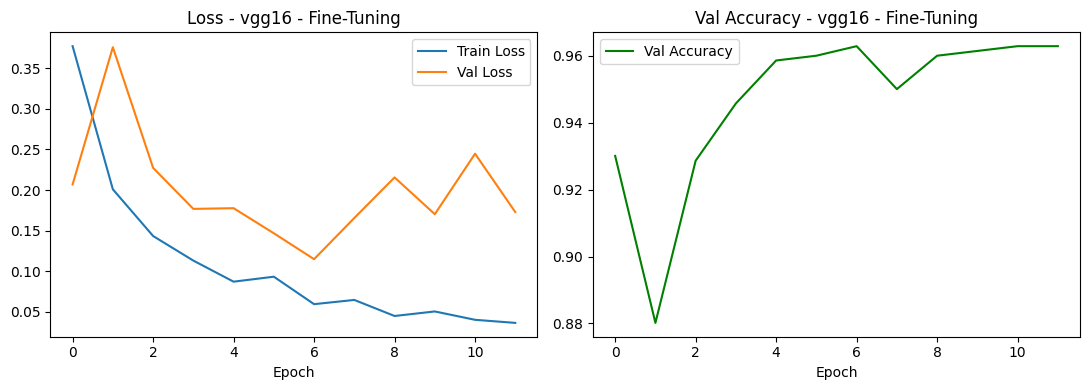


===== HASIL EVALUASI [vgg16 - Sesudah FT] =====
Accuracy : 0.9630
Precision: 0.9642
Recall   : 0.9633
F1-Score : 0.9635

              precision    recall  f1-score   support

      glioma       0.97      0.92      0.95       179
  meningioma       0.92      0.97      0.94       179
     notumor       0.99      0.98      0.99       168
   pituitary       0.98      0.98      0.98       176

    accuracy                           0.96       702
   macro avg       0.96      0.96      0.96       702
weighted avg       0.96      0.96      0.96       702



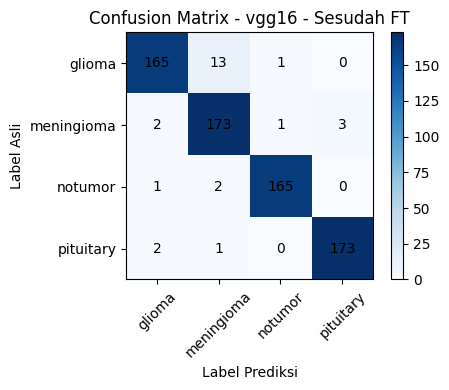


Ringkasan vgg16:
  Sebelum FT -> F1: 0.8930, Accuracy: 0.8917
  Sesudah FT -> F1: 0.9635, Accuracy: 0.9630
  Peningkatan F1  : +0.0704


In [18]:
all_results["vgg16"] = run_or_load("vgg16")

## ResNet-101


ARSITEKTUR: RESNET101
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[resnet101-before-FT] Epoch 01 | train_loss=0.6465 | val_loss=0.4643 | val_acc=0.8417 | 551.9s
[resnet101-before-FT] Epoch 02 | train_loss=0.4104 | val_loss=0.3853 | val_acc=0.8645 | 563.0s
[resnet101-before-FT] Epoch 03 | train_loss=0.3559 | val_loss=0.3409 | val_acc=0.8816 | 566.5s
[resnet101-before-FT] Epoch 04 | train_loss=0.3142 | val_loss=0.3323 | val_acc=0.8873 | 549.9s
[resnet101-before-FT] Epoch 05 | train_loss=0.2908 | val_loss=0.3076 | val_acc=0.8987 | 511.7s
[resnet101-before-FT] Epoch 06 | train_loss=0.2748 | val_loss=0.2933 | val_acc=0.8873 | 515.7s
[resnet101-before-FT] Epoch 07 | train_loss=0.2549 | val_loss=0.2867 | val_acc=0.9044 | 514.3s
[resnet101-before-FT] Epoch 08 | train_loss=0.2496 | val_loss=0.2682 | val_acc=0.8987 | 512.7s
[resnet101-before-FT] Epoch 09 | train_loss=0.2360 | val_loss=0.2583 | val_acc=0.9044 | 512.3s
[resnet101-before-FT] Epoch 10 | train_loss=0.2260 | val_

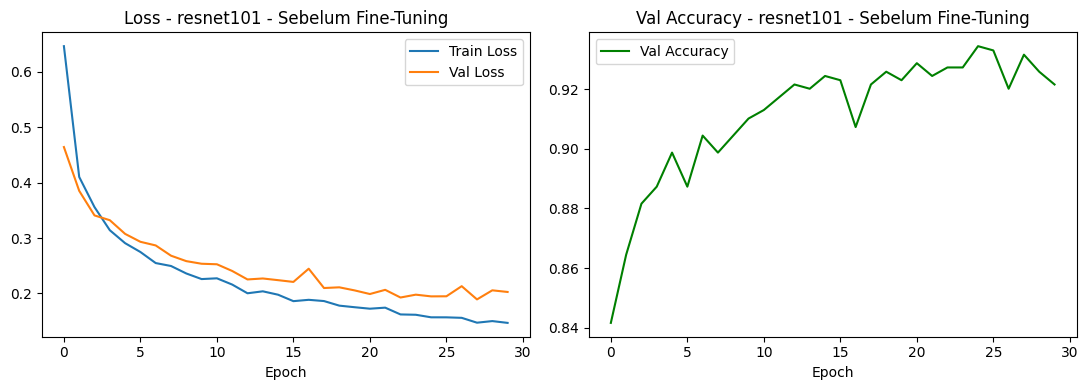


===== HASIL EVALUASI [resnet101 - Sebelum FT] =====
Accuracy : 0.9160
Precision: 0.9165
Recall   : 0.9170
F1-Score : 0.9164

              precision    recall  f1-score   support

      glioma       0.90      0.84      0.87       179
  meningioma       0.85      0.88      0.87       179
     notumor       0.94      0.97      0.96       168
   pituitary       0.97      0.98      0.97       176

    accuracy                           0.92       702
   macro avg       0.92      0.92      0.92       702
weighted avg       0.92      0.92      0.92       702



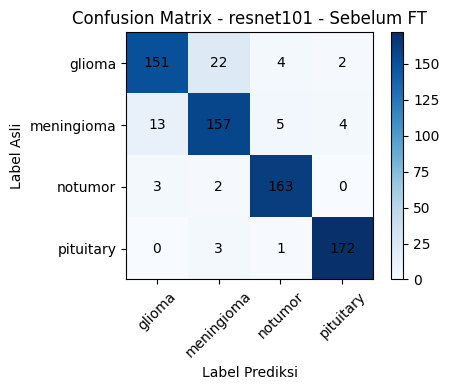

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 14,972,932
[resnet101-fine-tuning] Epoch 01 | train_loss=0.2124 | val_loss=0.1824 | val_acc=0.9315 | 584.9s
[resnet101-fine-tuning] Epoch 02 | train_loss=0.1200 | val_loss=0.1662 | val_acc=0.9529 | 587.1s
[resnet101-fine-tuning] Epoch 03 | train_loss=0.1003 | val_loss=0.1188 | val_acc=0.9615 | 596.4s
[resnet101-fine-tuning] Epoch 04 | train_loss=0.0671 | val_loss=0.1411 | val_acc=0.9658 | 592.6s
[resnet101-fine-tuning] Epoch 05 | train_loss=0.0524 | val_loss=0.1261 | val_acc=0.9572 | 592.2s
[resnet101-fine-tuning] Epoch 06 | train_loss=0.0423 | val_loss=0.1720 | val_acc=0.9572 | 612.3s
[resnet101-fine-tuning] Epoch 07 | train_loss=0.0383 | val_loss=0.1269 | val_acc=0.9715 | 601.1s
[resnet101-fine-tuning] Epoch 08 | train_loss=0.0439 | val_loss=0.0951 | val_acc=0.9800 | 596.2s
[resnet101-fine-tuning] Epoch 09 | train_loss=0.0238 | val_loss=0.1007 | val_acc=0.9800 | 594.2s
[resnet101-fine-t

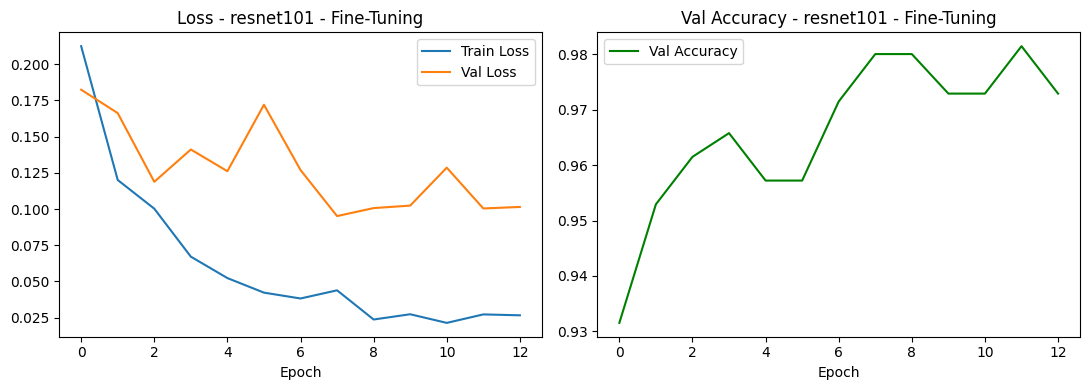


===== HASIL EVALUASI [resnet101 - Sesudah FT] =====
Accuracy : 0.9715
Precision: 0.9721
Recall   : 0.9717
F1-Score : 0.9718

              precision    recall  f1-score   support

      glioma       0.97      0.94      0.95       179
  meningioma       0.95      0.98      0.96       179
     notumor       0.98      0.98      0.98       168
   pituitary       0.99      0.98      0.99       176

    accuracy                           0.97       702
   macro avg       0.97      0.97      0.97       702
weighted avg       0.97      0.97      0.97       702



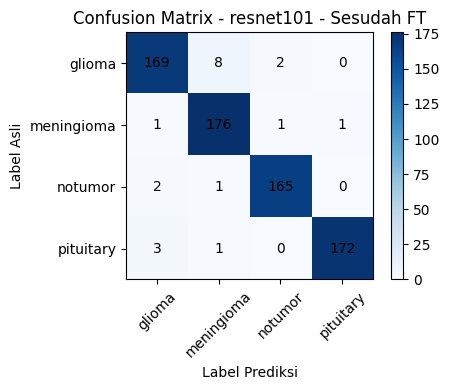


Ringkasan resnet101:
  Sebelum FT -> F1: 0.9164, Accuracy: 0.9160
  Sesudah FT -> F1: 0.9718, Accuracy: 0.9715
  Peningkatan F1  : +0.0553


In [19]:
all_results["resnet101"] = run_or_load("resnet101")

## GoogLeNet

In [21]:
all_results["googlenet"] = run_or_load("googlenet")

[googlenet] Hasil sudah ada di D:\Skripsi\results_final\googlenet_metrics.json, training dilewati.


## 11. Ringkasan, Interval Kepercayaan, dan Uji Statistik

In [22]:
ARCHS = ["vgg16", "resnet101", "googlenet"]

rows = []
for arch in ARCHS:
    with open(os.path.join(RESULTS_DIR, f"{arch}_metrics.json"), "r") as f:
        m = json.load(f)
    rows.append({
        "Arsitektur": arch,
        "Acc Sebelum FT": m["before"]["accuracy"],
        "F1 Sebelum FT": m["before"]["f1"],
        "Acc Sesudah FT": m["after"]["accuracy"],
        "F1 Sesudah FT": m["after"]["f1"],
        "Peningkatan F1": m["after"]["f1"] - m["before"]["f1"],
    })

df_summary = pd.DataFrame(rows).set_index("Arsitektur")
df_summary.to_csv(os.path.join(RESULTS_DIR, "summary.csv"))
df_summary.round(4)

,Acc Sebelum FT,F1 Sebelum FT,Acc Sesudah FT,F1 Sesudah FT,Peningkatan F1
Arsitektur,,,,,
vgg16,0.8917,0.8930,0.9630,0.9635,0.0704
resnet101,0.9160,0.9164,0.9715,0.9718,0.0553
googlenet,0.8917,0.8933,0.9687,0.9689,0.0756


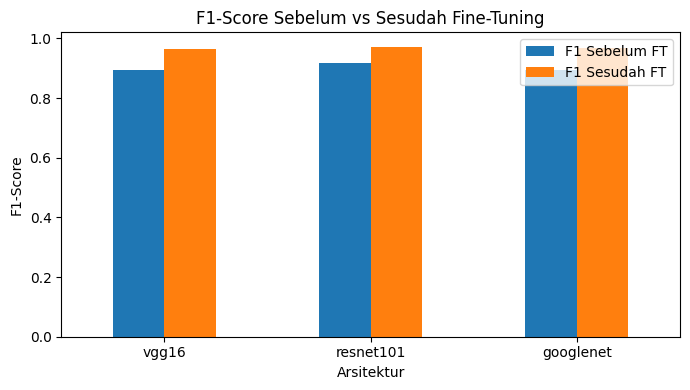

In [23]:
df_summary[["F1 Sebelum FT", "F1 Sesudah FT"]].plot(kind="bar", figsize=(7, 4))
plt.title("F1-Score Sebelum vs Sesudah Fine-Tuning")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interval kepercayaan 95% (bootstrap)

Test set berukuran terbatas, jadi selisih 1-2 poin antar model bisa saja hanya kebetulan.
Interval ini menunjukkan rentang wajar dari skor masing-masing model.

In [25]:
def bootstrap_ci(labels, pred, metric_fn, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(labels)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        scores.append(metric_fn(labels[idx], pred[idx]))
    return np.percentile(scores, [2.5, 97.5])

f1_macro = lambda y, p: f1_score(y, p, average="macro", zero_division=0)

ci_rows = []
for a in ARCHS:
    y = preds[a]["labels"]
    for stage in ["before", "after"]:
        p = preds[a][stage]
        lo_a, hi_a = bootstrap_ci(y, p, accuracy_score)
        lo_f, hi_f = bootstrap_ci(y, p, f1_macro)
        ci_rows.append({
            "Arsitektur": a,
            "Tahap": "Sebelum FT" if stage == "before" else "Sesudah FT",
            "Accuracy": f"{accuracy_score(y, p):.4f} [{lo_a:.4f} - {hi_a:.4f}]",
            "F1 macro": f"{f1_macro(y, p):.4f} [{lo_f:.4f} - {hi_f:.4f}]",
        })

pd.DataFrame(ci_rows).set_index(["Arsitektur", "Tahap"])

Accuracy                  F1 macro
Arsitektur Tahap                                                         
vgg16      Sebelum FT  0.8917 [0.8675 - 0.9145]  0.8930 [0.8694 - 0.9141]
           Sesudah FT  0.9630 [0.9487 - 0.9758]  0.9635 [0.9494 - 0.9762]
resnet101  Sebelum FT  0.9160 [0.8946 - 0.9359]  0.9164 [0.8947 - 0.9349]
           Sesudah FT  0.9715 [0.9587 - 0.9829]  0.9718 [0.9589 - 0.9829]
googlenet  Sebelum FT  0.8917 [0.8704 - 0.9145]  0.8933 [0.8720 - 0.9141]
           Sesudah FT  0.9687 [0.9558 - 0.9801]  0.9689 [0.9550 - 0.9806]

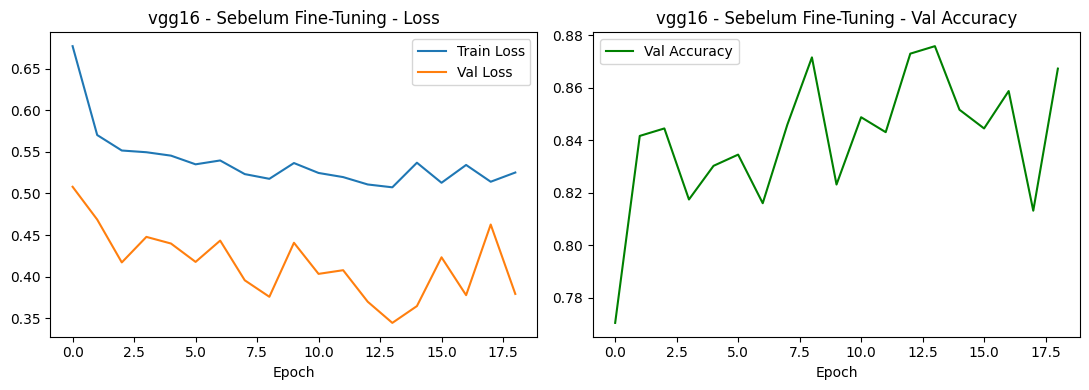

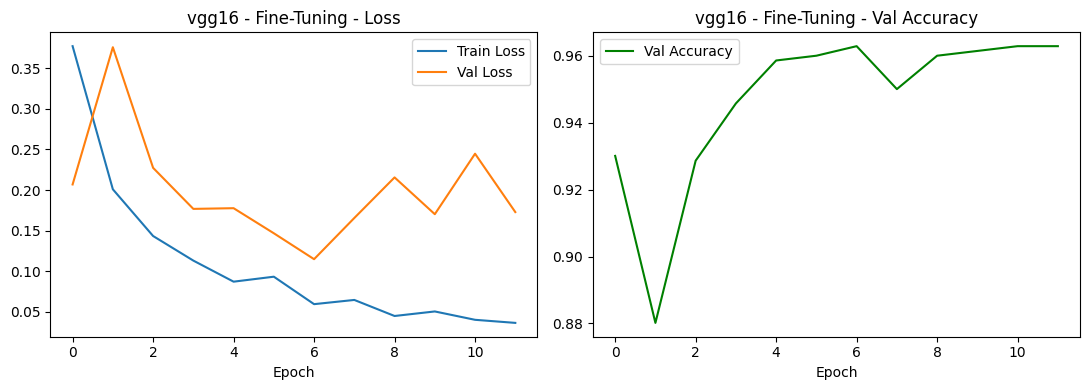

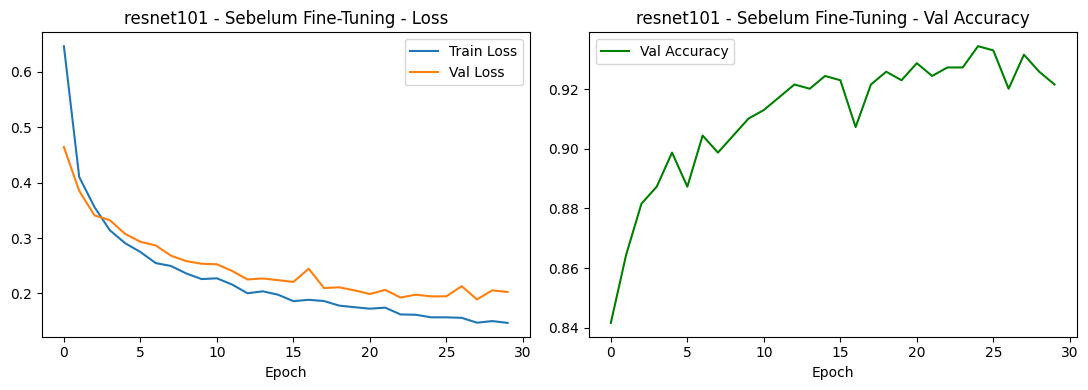

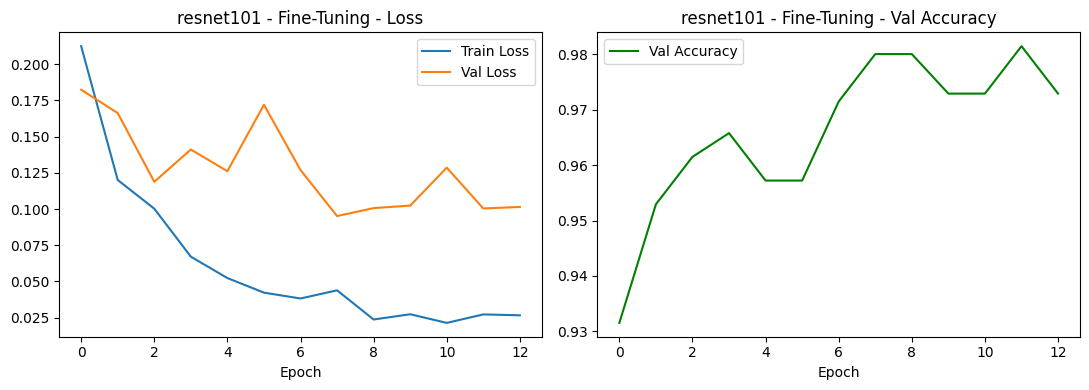

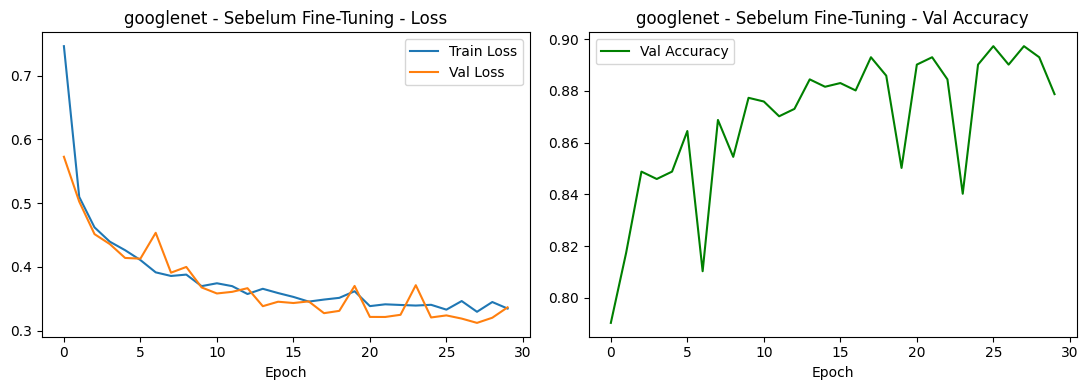

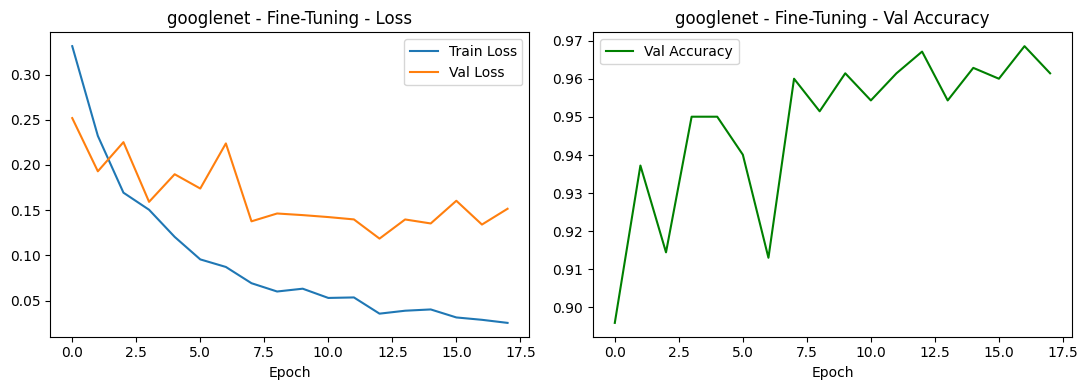

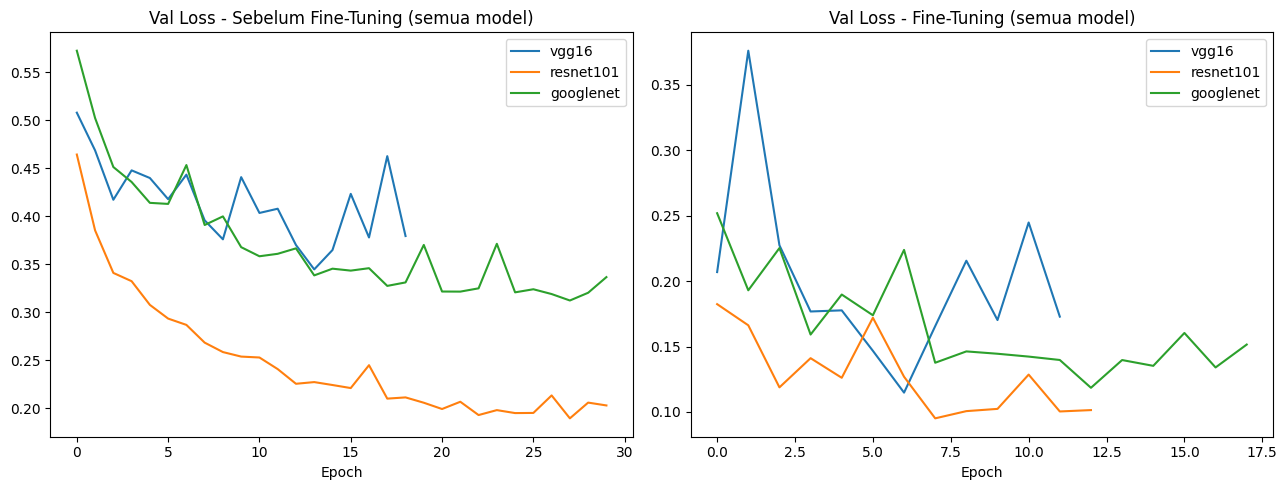

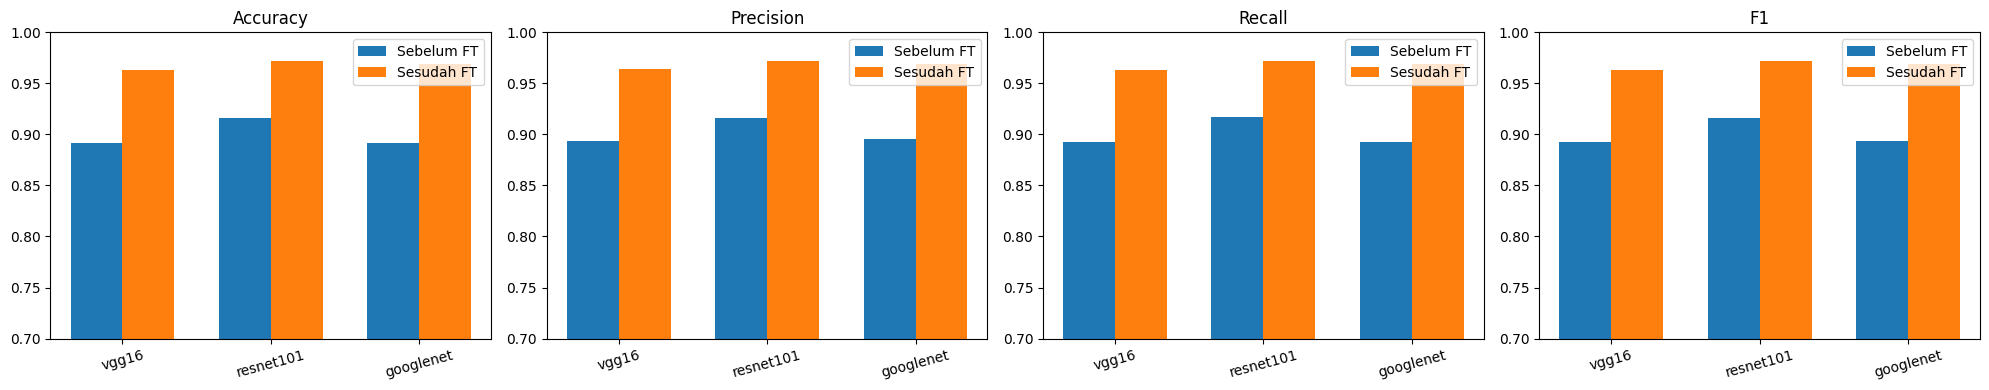

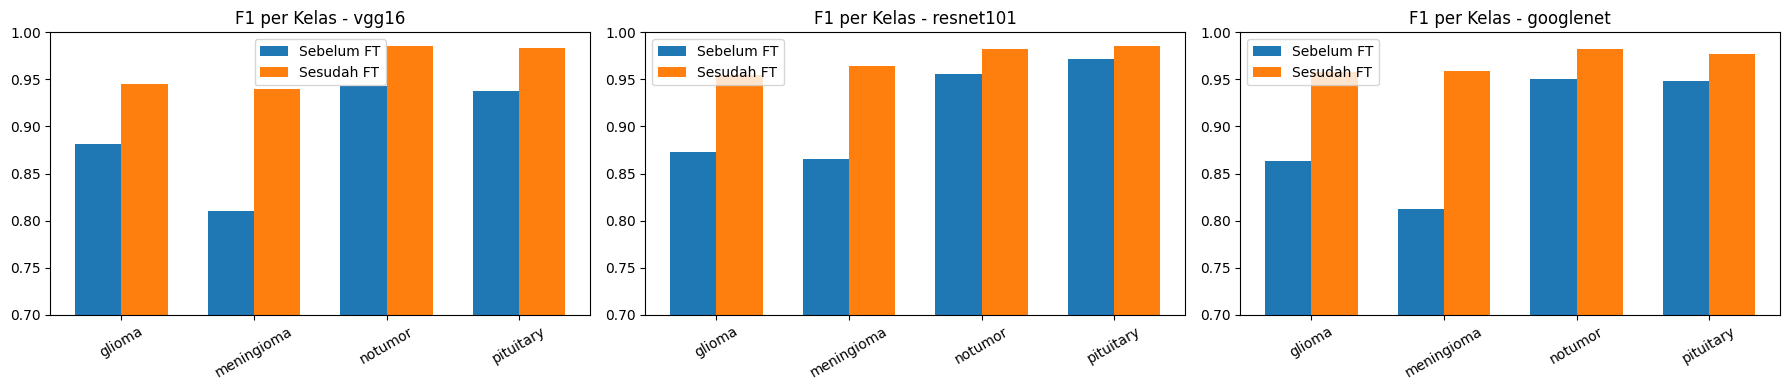

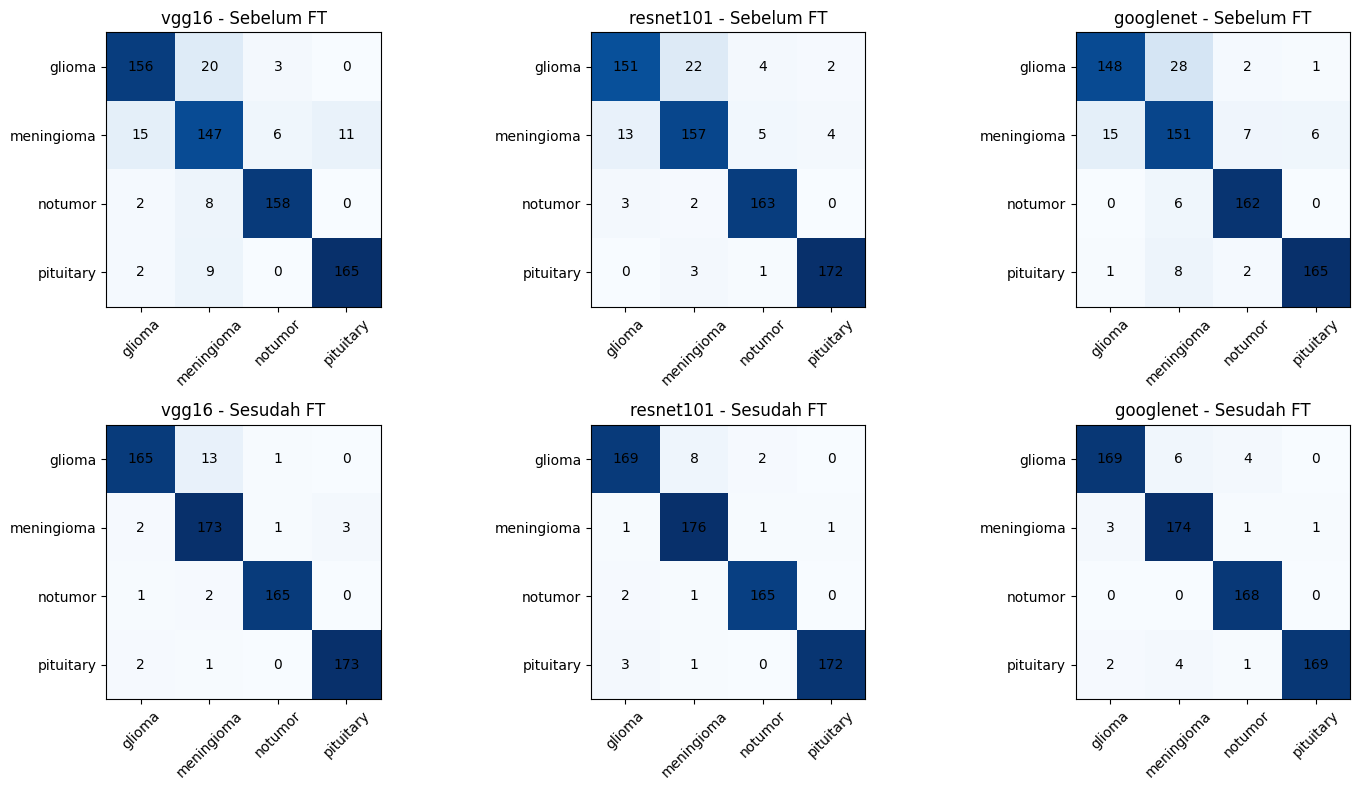

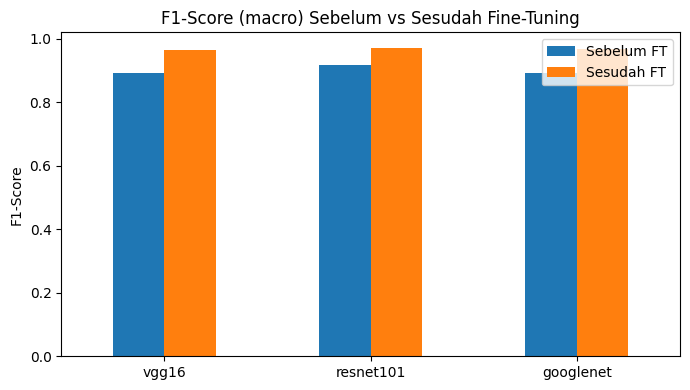

In [16]:
import os, json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

RESULTS_DIR = "results_final"   # ganti sesuai folder hasilmu
ARCHS = ["vgg16", "resnet101", "googlenet"]

with open(os.path.join(RESULTS_DIR, "class_names.json")) as f:
    class_names = json.load(f)

metrics = {a: json.load(open(os.path.join(RESULTS_DIR, f"{a}_metrics.json"))) for a in ARCHS}
history = {a: json.load(open(os.path.join(RESULTS_DIR, f"{a}_history.json"))) for a in ARCHS}
preds = {a: np.load(os.path.join(RESULTS_DIR, f"{a}_preds.npz")) for a in ARCHS}

# ===== 1. Kurva training tiap model: sebelum FT & fine-tuning (loss + accuracy) =====
for arch in ARCHS:
    for stage, label in [("before", "Sebelum Fine-Tuning"), ("ft", "Fine-Tuning")]:
        h = history[arch][stage]
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        axes[0].plot(h["train_loss"], label="Train Loss")
        axes[0].plot(h["val_loss"], label="Val Loss")
        axes[0].set_title(f"{arch} - {label} - Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].legend()

        axes[1].plot(h["val_acc"], label="Val Accuracy", color="green")
        axes[1].set_title(f"{arch} - {label} - Val Accuracy")
        axes[1].set_xlabel("Epoch")
        axes[1].legend()
        plt.tight_layout()
        plt.show()

# ===== 2. Semua kurva val_loss dalam satu grafik (bandingkan konvergensi antar model) =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for arch in ARCHS:
    axes[0].plot(history[arch]["before"]["val_loss"], label=arch)
    axes[1].plot(history[arch]["ft"]["val_loss"], label=arch)
axes[0].set_title("Val Loss - Sebelum Fine-Tuning (semua model)")
axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Val Loss - Fine-Tuning (semua model)")
axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

# ===== 3. Bar chart Accuracy, Precision, Recall, F1 - semua model, sebelum vs sesudah =====
metric_names = ["accuracy", "precision", "recall", "f1"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
x = np.arange(len(ARCHS))
width = 0.35
for i, mname in enumerate(metric_names):
    before_vals = [metrics[a]["before"][mname] for a in ARCHS]
    after_vals = [metrics[a]["after"][mname] for a in ARCHS]
    axes[i].bar(x - width/2, before_vals, width, label="Sebelum FT")
    axes[i].bar(x + width/2, after_vals, width, label="Sesudah FT")
    axes[i].set_title(mname.capitalize())
    axes[i].set_xticks(x); axes[i].set_xticklabels(ARCHS, rotation=15)
    axes[i].set_ylim(0.7, 1.0)
    axes[i].legend()
plt.tight_layout()
plt.show()

# ===== 4. F1 per kelas - sebelum vs sesudah, tiap model (grouped bar) =====
fig, axes = plt.subplots(1, len(ARCHS), figsize=(6 * len(ARCHS), 4))
for ax, arch in zip(axes, ARCHS):
    rep_before = classification_report(preds[arch]["labels"], preds[arch]["before"],
                                        target_names=class_names, output_dict=True, zero_division=0)
    rep_after = classification_report(preds[arch]["labels"], preds[arch]["after"],
                                       target_names=class_names, output_dict=True, zero_division=0)
    f1_before = [rep_before[c]["f1-score"] for c in class_names]
    f1_after = [rep_after[c]["f1-score"] for c in class_names]
    xc = np.arange(len(class_names))
    ax.bar(xc - width/2, f1_before, width, label="Sebelum FT")
    ax.bar(xc + width/2, f1_after, width, label="Sesudah FT")
    ax.set_title(f"F1 per Kelas - {arch}")
    ax.set_xticks(xc); ax.set_xticklabels(class_names, rotation=30)
    ax.set_ylim(0.7, 1.0)
    ax.legend()
plt.tight_layout()
plt.show()

# ===== 5. Confusion matrix semua model, sebelum vs sesudah (2 baris x 3 kolom) =====
fig, axes = plt.subplots(2, len(ARCHS), figsize=(5 * len(ARCHS), 8))
for col, arch in enumerate(ARCHS):
    for row, (stage, label) in enumerate([("before", "Sebelum FT"), ("after", "Sesudah FT")]):
        cm = confusion_matrix(preds[arch]["labels"], preds[arch][stage])
        ax = axes[row, col]
        ax.imshow(cm, cmap="Blues")
        ax.set_title(f"{arch} - {label}")
        ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=45)
        ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
        for i in range(len(class_names)):
            for j in range(len(class_names)):
                ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

# ===== 6. F1-Score keseluruhan (macro) - bar chart utama =====
df_f1 = pd.DataFrame({
    "Sebelum FT": [metrics[a]["before"]["f1"] for a in ARCHS],
    "Sesudah FT": [metrics[a]["after"]["f1"] for a in ARCHS],
}, index=ARCHS)
df_f1.plot(kind="bar", figsize=(7, 4))
plt.title("F1-Score (macro) Sebelum vs Sesudah Fine-Tuning")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()